# 04 · Fine-tune: GLM 5.3 Flash vision LoRA on train buildings

3,000 training questions (counting + presence) from the ≈930 **training buildings** only, each `[plan image, question] → one short sentence + the answer`. Serverless vision LoRA (rank 16, LR 1e-4, 1 epoch, batch 16 → ≈190 steps), scored on the 1,000 test questions in-session, then promoted automatically.

In [1]:
import asyncio, json, os, sys
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "fp_common.py").exists():
    HERE = Path("experiments/floorplancad-symbol-counting").resolve()
os.chdir(HERE)
sys.path.insert(0, str(HERE))

import fp_common as f
import fp_report as rep
rep.fv.apply_theme()
print(f.build(), "· API key set:", bool(os.getenv("FIREWORKS_API_KEY")))
import fw_utils as fw

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 6219, 'test': 1000} · API key set: True


## Train + score + promote (background job, ≈1–1.5 h)

In [2]:
fw.start("glm_sft", ["fp_sft.py", "--tag", "glm_sft", "--n-train", "3000", "--epochs", "1", "--batch-size", "16"])

glm_sft already done: results/results_glm_sft.jsonl exists. Delete it to run again.


In [3]:
fw.watch("glm_sft")

{"step": 170, "epoch": 1, "loss": 0.0596}
{"step": 180, "epoch": 1, "loss": 0.0678}
scoring test n=1000…
prefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead
  scored 200/1000
  scored 400/1000
  scored 600/1000
  scored 800/1000
  scored 1000/1000
glm_sft: accuracy 78.4%
promoted accounts/pyroworks/models/fp-off-glm-sft-20261031-094440
serverless session closed

— glm_sft finished —


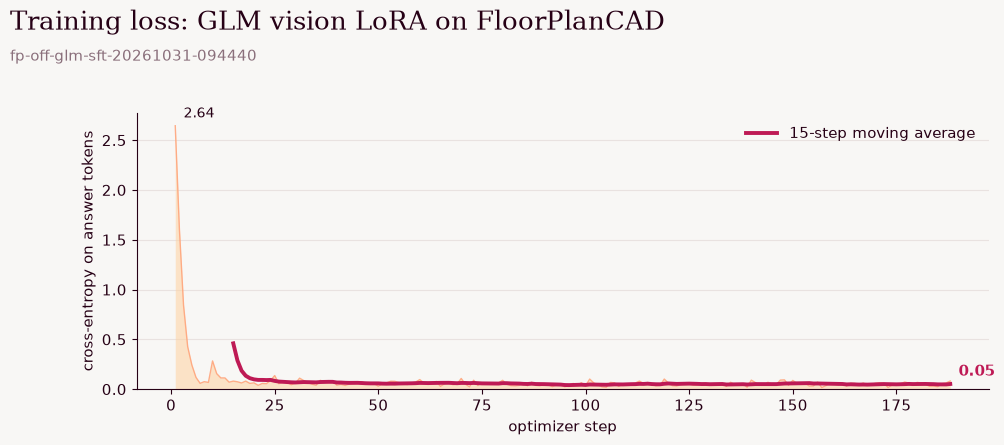

In [4]:
runs = [p for p in sorted((HERE / "sft_logs").glob("fp-off-glm-sft-*/metrics.jsonl")) if p.read_text().strip()]
if runs:
    rep.fv.loss_curve(runs[-1], "Training loss: GLM vision LoRA on FloorPlanCAD", runs[-1].parent.name, save="loss_curve")

## Results

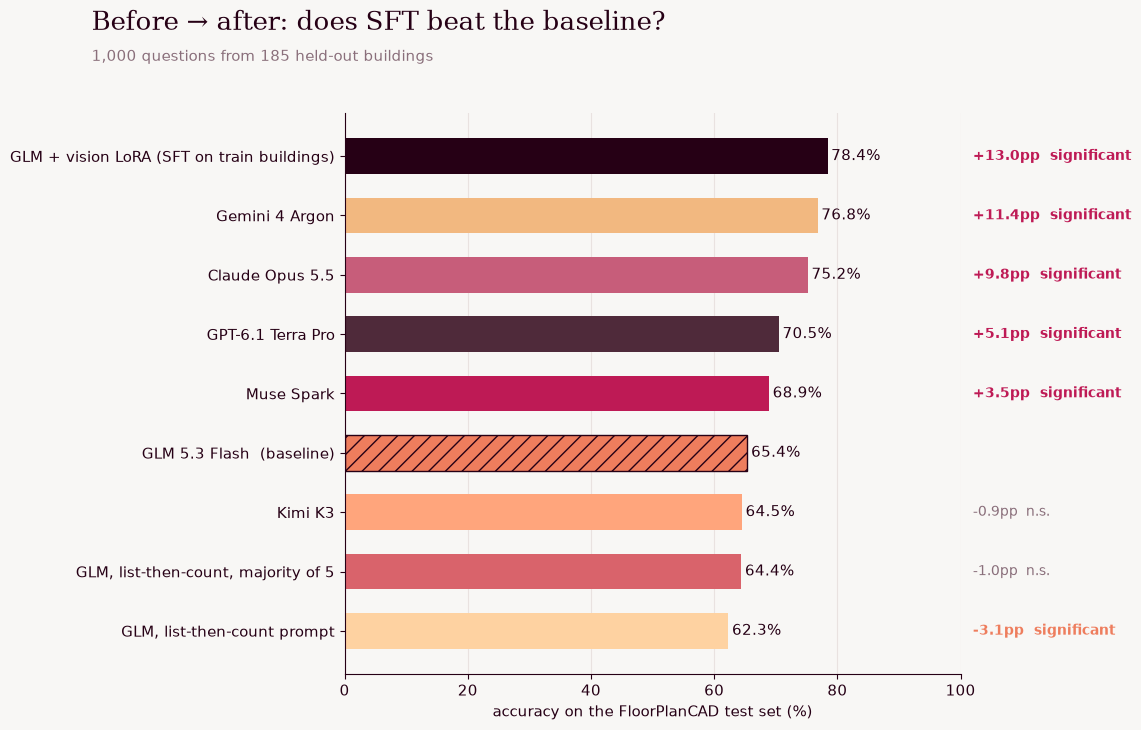

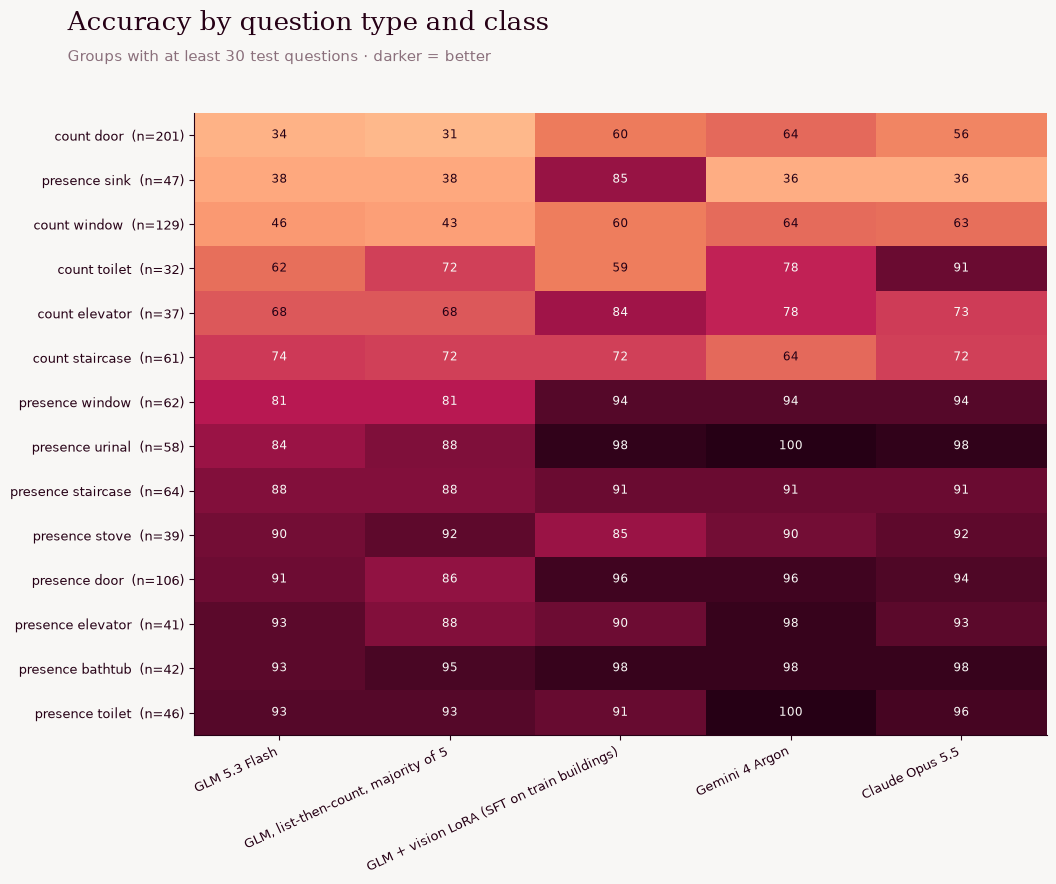

,n,acc_a,acc_b,Δpp,only_a,only_b,McNemar p,boot 95% CI,significant,notes
pair,,,,,,,,,,
GLM + vision LoRA (SFT on train buildings) vs GLM 5.3 Flash,1000,78.4%,65.4%,13.0,178,48,0.0000,"[+9.8, +16.0]",True,GAIN holds under both tests
"GLM + vision LoRA (SFT on train buildings) vs GLM, list-then-count, majority of 5",1000,78.4%,64.4%,14.0,201,61,0.0000,"[+10.7, +17.2]",True,GAIN holds under both tests
GLM + vision LoRA (SFT on train buildings) vs Gemini 4 Argon,1000,78.4%,76.8%,1.6,103,87,0.2765,"[-1.4, +4.4]",False,within noise
GLM + vision LoRA (SFT on train buildings) vs Claude Opus 5.5,1000,78.4%,75.2%,3.2,118,86,0.0297,"[+0.3, +6.1]",True,GAIN holds under both tests
GLM + vision LoRA (SFT on train buildings) vs GPT-6.1 Terra Pro,1000,78.4%,70.5%,7.9,151,72,0.0000,"[+5.0, +10.7]",True,GAIN holds under both tests


,n,acc_a,acc_b,Δpp,only_a,only_b,McNemar p,boot 95% CI,significant,notes
pair,,,,,,,,,,
GLM + vision LoRA (SFT on train buildings) vs GLM 5.3 Flash,1000,78.4%,65.4%,13.0,178,48,0.0000,"[+9.8, +16.0]",True,GAIN holds under both tests
"GLM + vision LoRA (SFT on train buildings) vs GLM, list-then-count, majority of 5",1000,78.4%,64.4%,14.0,201,61,0.0000,"[+10.7, +17.2]",True,GAIN holds under both tests
GLM + vision LoRA (SFT on train buildings) vs Gemini 4 Argon,1000,78.4%,76.8%,1.6,103,87,0.2765,"[-1.4, +4.4]",False,within noise
GLM + vision LoRA (SFT on train buildings) vs Claude Opus 5.5,1000,78.4%,75.2%,3.2,118,86,0.0297,"[+0.3, +6.1]",True,GAIN holds under both tests
GLM + vision LoRA (SFT on train buildings) vs GPT-6.1 Terra Pro,1000,78.4%,70.5%,7.9,151,72,0.0000,"[+5.0, +10.7]",True,GAIN holds under both tests


In [5]:
rep.leaderboard(["glm", "glm_enum", "glm_enum_vote", "glm_sft", "muse", "kimi", "gemini4", "opus55", "gpt61"], "glm",
                "Before → after: does SFT beat the baseline?", "1,000 questions from 185 held-out buildings", save="leaderboard")
rep.class_heatmap(["glm", "glm_enum_vote", "glm_sft", "gemini4", "opus55"], save="per_class")
rep.significance_table([("glm_sft", "glm"), ("glm_sft", "glm_enum_vote"), ("glm_sft", "gemini4"), ("glm_sft", "opus55"), ("glm_sft", "gpt61")])

**The two tests in pictures.** McNemar: do the disagreements split like a coin flip? Bootstrap: across 5,000 fake test sets, does the gap stay on one side of zero?

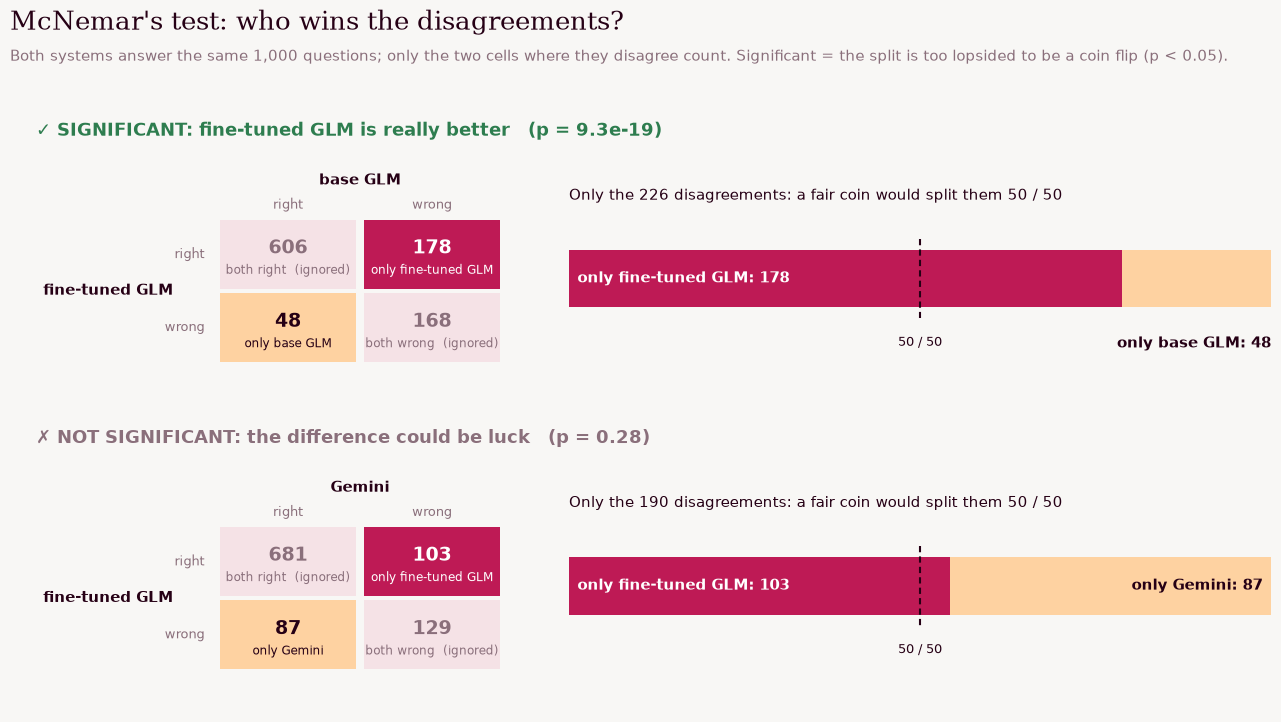

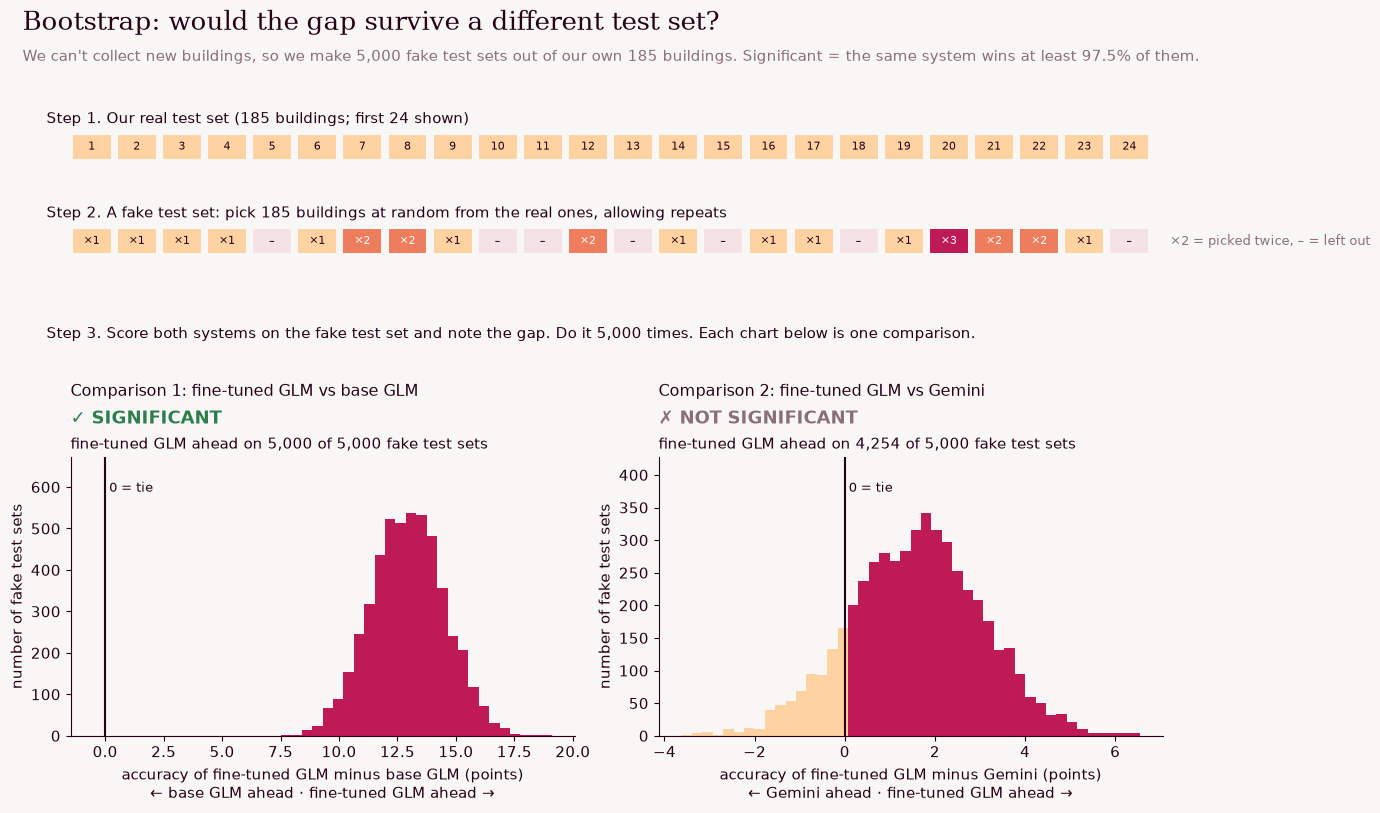

In [6]:
rep.fv.mcnemar_figure(
    [("fine-tuned GLM", "base GLM", "not a coin flip", rep.compare("glm_sft", "glm")),
     ("fine-tuned GLM", "Gemini", "could be a coin flip", rep.compare("glm_sft", "gemini4"))],
    unit="question", n_items=1000, save="significance_mcnemar")
rep.fv.bootstrap_figure(
    [("fine-tuned GLM", "base GLM", rep.compare("glm_sft", "glm")),
     ("fine-tuned GLM", "Gemini", rep.compare("glm_sft", "gemini4"))],
    n_clusters=185, cluster="building", metric="accuracy", save="significance_bootstrap")

**Stats.** McNemar on paired right/wrong per question, plus a bootstrap that resamples whole *buildings* (tiles from one building are correlated). A gain counts only when both are significant.